# Modern Packaging & Environments with uv

A Python project needs three things to be reproducible: an **isolated environment**, a **list of dependencies**, and a **lock file** that pins every version. For many years this required several tools (`venv`, `pip`, `pip-tools`, `virtualenv`, Poetry, pyenv). **uv** replaces them with one fast tool.

**After this lesson you can:**

1. Explain what a virtual environment is and create one with `venv` and with uv.
2. Describe `pyproject.toml`, dependency groups and the lock file.
3. Create, run, build and package a project with uv.
4. Compare uv with pip, Poetry and conda.

Every command in this lesson runs for real, in a temporary folder.

## 1. Virtual Environments

A **virtual environment** is a folder with its own Python interpreter link and its own `site-packages` folder. Packages that you install there do not affect other projects or the system Python.

The standard library module `venv` creates one:

```bash
python -m venv .venv
source .venv/bin/activate        # Windows: .venv\Scripts\activate
pip install requests
```

The cell creates an environment and shows its structure.

In [1]:
import os
import shutil
import subprocess
import sys
import tempfile
import time
from pathlib import Path

work = Path(tempfile.mkdtemp())
venv_dir = work / "classic-venv"
t0 = time.perf_counter()
subprocess.run([sys.executable, "-m", "venv", str(venv_dir)], check=True)
venv_time = time.perf_counter() - t0

bin_dir = venv_dir / ("Scripts" if os.name == "nt" else "bin")
print(f"created in {venv_time:.2f} s")
print("top-level items:", sorted(p.name for p in venv_dir.iterdir()))
print("executables    :", sorted(p.name for p in bin_dir.iterdir())[:8])
print((venv_dir / "pyvenv.cfg").read_text().replace(str(Path.cwd().parent), "<repo>").replace(str(work), "<tmp>").replace(str(Path.home()), "~"))

created in 2.39 s
top-level items: ['bin', 'include', 'lib', 'lib64', 'pyvenv.cfg']
executables    : ['Activate.ps1', 'activate', 'activate.csh', 'activate.fish', 'pip', 'pip3', 'pip3.12', 'python']
home = ~/.local/share/uv/python/cpython-3.12-linux-x86_64-gnu/bin
include-system-site-packages = false
version = 3.12.16
executable = ~/.local/share/uv/python/cpython-3.12.16-linux-x86_64-gnu/bin/python3.12
command = <repo>/.venv/bin/python -m venv <tmp>/classic-venv



`pyvenv.cfg` points to the base interpreter. The environment contains `pip`, but no other packages. The old workflow records dependencies with `pip freeze > requirements.txt`. That file mixes the packages you asked for with all their sub-dependencies, and it has no information about Python versions or platforms.

## 2. `pyproject.toml` and the Lock File

Modern Python projects describe themselves in **`pyproject.toml`** (PEP 621):

| Section | Content |
| :--- | :--- |
| `[project]` | name, version, `requires-python`, **direct** dependencies |
| `[dependency-groups]` | optional groups, e.g. `dev = ["pytest"]` (PEP 735) |
| `[project.scripts]` | command-line commands that the package installs |
| `[build-system]` | how to build a wheel |
| `[tool.*]` | settings for tools (uv, ruff, pytest, mypy) |

The **lock file** (`uv.lock`) records the **exact** version and hash of every package, including sub-dependencies, for every platform. Commit both files to Git.

## 3. A Project with uv

The workflow:

1. `uv init` creates a project with `pyproject.toml`.
2. `uv add` adds a dependency and updates the lock file.
3. `uv run` runs a command in the project environment (uv creates or updates `.venv` automatically).
4. `uv build` builds a distributable **wheel**.

In [2]:
uv = shutil.which("uv")
if uv is None:
    raise SystemExit("uv is not installed: run `pip install uv` (see Lesson 01 of M01)")

def sh(*args, cwd=work):
    r = subprocess.run([uv, *args], cwd=cwd, capture_output=True, text=True)
    out = (r.stdout + r.stderr).strip().replace(str(work), "<tmp>").replace(str(Path.home()), "~")
    print(f"$ uv {' '.join(a.replace(str(work), '<tmp>') for a in args)}\n{out}\n")
    return r

sh("--version")
sh("init", "--package", "--name", "tiny-stats", "--python", "3.12", "tiny-stats")
project = work / "tiny-stats"
print(sorted(p.relative_to(project).as_posix() for p in project.rglob("*") if ".git" not in p.parts))

$ uv --version
uv 0.13.8 (x86_64-unknown-linux-gnu)

$ uv init --package --name tiny-stats --python 3.12 tiny-stats
Initialized project `tiny-stats` at `<tmp>/tiny-stats`

['.gitignore', '.python-version', 'README.md', 'pyproject.toml', 'src', 'src/tiny_stats', 'src/tiny_stats/__init__.py']


In [3]:
(project / "src" / "tiny_stats" / "__init__.py").write_text("""# Tiny statistics helpers.
from statistics import mean, pstdev


def zscores(values: list[float]) -> list[float]:
    # Standardise values to mean 0 and standard deviation 1.
    m, s = mean(values), pstdev(values)
    return [(v - m) / s for v in values]


def main() -> None:
    from rich import print as rprint
    rprint("[bold green]z-scores:[/]", [round(z, 2) for z in zscores([2, 4, 4, 4, 5, 5, 7, 9])])
""")

sh("add", "rich>=13", cwd=project)
sh("add", "--dev", "pytest", cwd=project)
print((project / "pyproject.toml").read_text())

$ uv add rich>=13
Using CPython 3.12.16
Creating virtual environment at: .venv
Resolved 5 packages in 348ms
   Building tiny-stats @ file://<tmp>/tiny-stats
      Built tiny-stats @ file://<tmp>/tiny-stats
Prepared 1 package in 6ms
Installed 5 packages in 28ms
 + markdown-it-py==4.3.0
 + mdurl==0.1.2
 + pygments==2.21.0
 + rich==15.0.0
 + tiny-stats==0.1.0 (from file://<tmp>/tiny-stats)

$ uv add --dev pytest
Resolved 10 packages in 4ms
   Building tiny-stats @ file://<tmp>/tiny-stats
      Built tiny-stats @ file://<tmp>/tiny-stats
Prepared 1 package in 4ms
Uninstalled 1 package in 0.39ms
Installed 5 packages in 4ms
 + iniconfig==2.3.1
 + packaging==26.3
 + pluggy==1.7.0
 + pytest==9.2.0
 ~ tiny-stats==0.1.0 (from file://<tmp>/tiny-stats)

[project]
name = "tiny-stats"
version = "0.1.0"
description = "Add your description here"
readme = "README.md"
authors = [
    { name = "MuhammetAliVarlik", email = "iletisim.muhammetalivarlik@gmail.com" }
]
requires-python = ">=3.12"
dependencies =

`uv add` wrote the direct dependency (`rich`) into `[project]` and `pytest` into the `dev` group. It also resolved all versions and wrote `uv.lock`. The `[project.scripts]` entry, created by `uv init --package`, defines the command `tiny-stats`.

In [4]:
lock = (project / "uv.lock").read_text().splitlines()
print(f"uv.lock: {len(lock)} lines; first package entries:")
print("\n".join([l for l in lock if l.startswith(("name =", "version ="))][:8]))

sh("run", "tiny-stats", cwd=project)
sh("tree", "--depth", "2", cwd=project)
sh("build", cwd=project)
print("built files:", sorted(p.name for p in (project / "dist").iterdir()))

uv.lock: 117 lines; first package entries:
version = 1
name = "colorama"
version = "0.4.6"
name = "iniconfig"
version = "2.3.1"
name = "markdown-it-py"
version = "4.3.0"
name = "mdurl"


$ uv run tiny-stats
z-scores:
[-1.5, -0.5, -0.5, -0.5, 0.0, 0.0, 1.0, 2.0]

$ uv tree --depth 2
tiny-stats v0.1.0
├── rich v15.0.0
│   ├── markdown-it-py v4.3.0
│   └── pygments v2.21.0
└── pytest v9.2.0 (group: dev)
    ├── iniconfig v2.3.1
    ├── packaging v26.3
    ├── pluggy v1.7.0
    └── pygments v2.21.0
Resolved 10 packages in 0.77ms

$ uv build
Building source distribution...
Successfully built dist/tiny_stats-0.1.0.tar.gz
Successfully built dist/tiny_stats-0.1.0-py3-none-any.whl

built files: ['.gitignore', 'tiny_stats-0.1.0-py3-none-any.whl', 'tiny_stats-0.1.0.tar.gz']


The project now has a lock file, a working command and a **wheel** (`.whl`) that anyone can install with `pip install` or `uv pip install`. `uv publish` uploads the wheel to PyPI.

## 4. Speed: pip vs uv

uv is written in Rust and uses a global cache with hard links. The experiment creates a new environment and installs the same package (`rich` and its dependencies) with both tools. Both tools may use their caches, so the measurement shows the time of a typical repeated install.

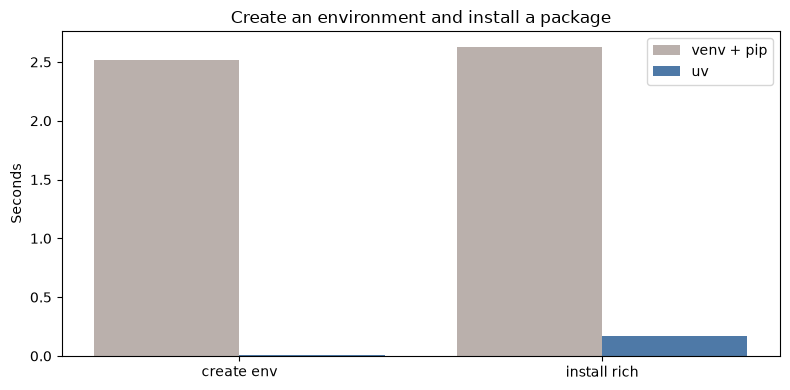

create env    pip  2.52 s | uv  0.01 s | 234.0x faster
install rich  pip  2.63 s | uv  0.17 s | 15.7x faster


In [5]:
import matplotlib.pyplot as plt

def timed(cmd, cwd=work):
    t = time.perf_counter()
    subprocess.run(cmd, cwd=cwd, capture_output=True, check=True)
    return time.perf_counter() - t

pip_env, uv_env = work / "pip-env", work / "uv-env"
times = {
    "create env": (timed([sys.executable, "-m", "venv", str(pip_env)]), timed([uv, "venv", "-q", str(uv_env)])),
    "install rich": (
        timed([str(pip_env / "bin" / "python"), "-m", "pip", "install", "-q", "rich"]),
        timed([uv, "pip", "install", "-q", "--python", str(uv_env / "bin" / "python"), "rich"]),
    ),
}

fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(times))
ax.bar([i - 0.2 for i in x], [v[0] for v in times.values()], width=0.4, color="#BAB0AC", label="venv + pip")
ax.bar([i + 0.2 for i in x], [v[1] for v in times.values()], width=0.4, color="#4E79A7", label="uv")
ax.set_xticks(list(x), list(times))
ax.set(title="Create an environment and install a package", ylabel="Seconds")
ax.legend()
plt.tight_layout()
plt.show()
for step, (p, u) in times.items():
    print(f"{step:<13} pip {p:5.2f} s | uv {u:5.2f} s | {p / u:4.1f}x faster")

## 5. uv Compared with Other Tools

| Task | Classic tools | Poetry | conda / Miniforge | uv |
| :--- | :--- | :--- | :--- | :--- |
| Install Python versions | pyenv | — | yes | `uv python install` |
| Create environments | venv, virtualenv | yes | yes | `uv venv`, automatic |
| Lock file (cross-platform) | pip-tools (partial) | `poetry.lock` | conda-lock (extra tool) | `uv.lock` |
| Build and publish | build, twine | yes | conda-build | `uv build`, `uv publish` |
| Run tools without installing | pipx | — | — | `uvx ruff check .` |
| Non-Python packages (C libs, CUDA) | no | no | **yes** | no (uses wheels) |

**When to use conda:** when you need non-Python binaries that are not available as wheels, for example some geospatial or bioinformatics stacks. Use the free **Miniforge** distribution with the conda-forge channel.

*Insight: Put `pyproject.toml` and the lock file in Git, never the environment folder. With these two files, anyone (and any CI server) can rebuild exactly the same environment with one command: `uv sync`.*

## Real-World Use Case or Analogy

`pyproject.toml` is the **shopping list**: "tomatoes, pasta, cheese". The lock file is the **receipt**: the exact brand, size and batch of each item. With only the list, two people come home with different products. With the receipt, everybody cooks with exactly the same ingredients.

Teams use the same files in three places: on developer laptops (`uv sync`), in CI pipelines that run the tests (M34), and in Docker images for production (M32). Because all three use the same lock file, a bug that appears in production can be reproduced on a laptop.